<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb

In [ ]:
! pip install tensorflow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [61]:
import wfdb
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, Flatten
import joblib

In [ ]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder))

['104.atr', '121.atr', '222.at_', '201.xws', '230.xws', '117.hea', '105.xws', '234.atr', '117.at_', '209.dat', '116.atr', '112.hea', '213.xws', '214.dat', '214.hea', '103.xws', '201.hea', '113.dat', '115.xws', '230.hea', '105.dat', '118.xws', '118.atr', '106.xws', '203.atr', '215.dat', '201.dat', '114.xws', '202.atr', '115.hea', '234.xws', '202.xws', '124.dat', '103.atr', '230.dat', 'ANNOTATORS', '207.hea', '215.atr', '109.dat', '203.dat', '123.xws', '215.hea', '219.hea', '203.hea', '209.atr', '109.hea', '232.atr', '118.dat', '207.xws', '104.xws', '222.hea', '221.hea', '114.dat', '102.xws', '221.atr', '230.atr', '123.dat', '106.dat', '122.hea', '115.dat', '106.hea', '121.dat', '202.dat', '102.atr', '219.xws', '223.atr', '101.atr', '208.dat', '203.xws', '212.atr', '102-0.atr', '108.hea', '232.dat', '102.hea', '232.xws', '107.dat', '123.hea', '201.atr', '220.dat', '109.atr', '105.hea', '104.hea', '108.xws', '104.dat', '217.atr', '231.hea', '114.hea', '231.atr', '213.dat', '208.atr', '117

In [ ]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [ ]:
all_labels = []  # عشان اجوف كل الرموز اللي في الديتا سيت و شلون اخليهم مع بعض عقب
signals = []
for file in files:  # هاي الرموز ف ديتا سيت و صنفناهم  ع حسب المعيار العلمي

    if file.endswith('.hea'):

        name = file.replace('.hea', '')
        record = wfdb.rdrecord(folder + '/' + name)
        signal = record.p_signal[:, 0]
        signals.append(signal)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        all_labels = all_labels + annotation.symbol

print("Signals:", len(signals))
print("Labels:", len(all_labels))
print("Label Types:", set(all_labels))


Signals: 48
Labels: 112647
Label Types: {'S', 'J', 'e', 'A', 'V', 'R', 'F', 'L', '"', '/', '+', 'N', '|', 'Q', 'j', ']', '~', 'a', 'f', '!', 'E', 'x', '['}


In [ ]:
# convert all clissy to aami in all records
N = all_labels.count('N') + all_labels.count('L') + all_labels.count('R') + all_labels.count('e') + all_labels.count('j')

S = all_labels.count('A') + all_labels.count('a') + all_labels.count('J') + all_labels.count('S')

V = all_labels.count('V') + all_labels.count('E')

F = all_labels.count('F')

Q = all_labels.count('/') + all_labels.count('f') + all_labels.count('Q')

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


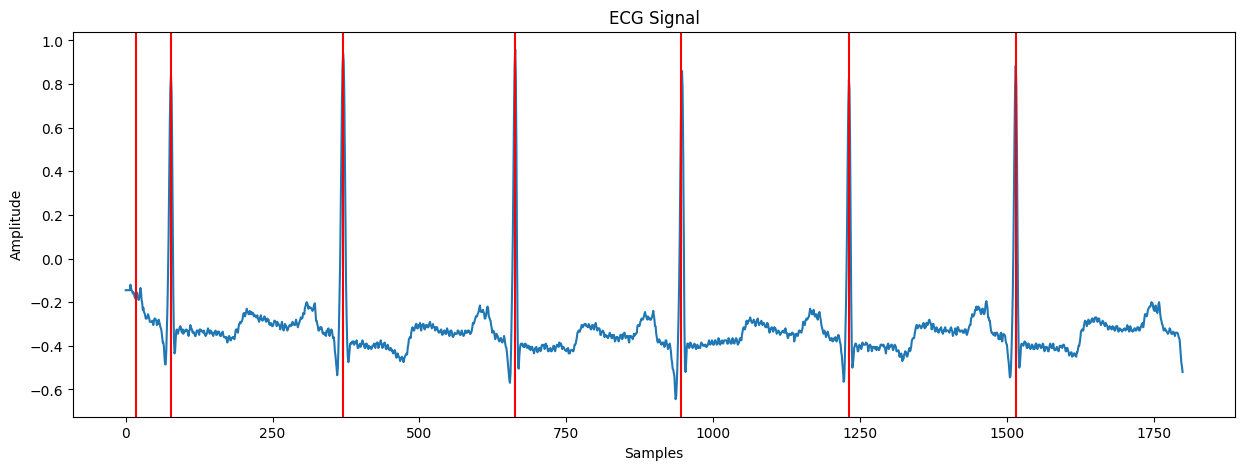

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
# Heartbeat to prepare the data to train models

In [ ]:
# i will prapare the data to 48 record

In [ ]:
X = []
y = []

for file in files:

    if file.endswith('.hea'):

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(annotation.sample)):

            peak = annotation.sample[i]
            label = annotation.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (101396, 360)
Y Shape: (101396,)


In [ ]:
# model 1 split the data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42,stratify=y_train)

In [ ]:
# model 1 binary label 0=normal / 1=abnormal

In [ ]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [ ]:
## dt for bainary model

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9058
           1       0.86      0.87      0.86      1082

    accuracy                           0.97     10140
   macro avg       0.92      0.93      0.92     10140
weighted avg       0.97      0.97      0.97     10140



In [ ]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18117
           1       0.86      0.87      0.86      2163

    accuracy                           0.97     20280
   macro avg       0.92      0.92      0.92     20280
weighted avg       0.97      0.97      0.97     20280



In [ ]:
# knn model

In [ ]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.97      0.91      0.94      1082

    accuracy                           0.99     10140
   macro avg       0.98      0.95      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [ ]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.97      0.91      0.94      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.95      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [ ]:
# cnn model

In [28]:
encoder = LabelEncoder()
encoder.fit(y_train[y_train != 'N'])
y_train_encoded = np.zeros(len(y_train))
y_val_encoded = np.zeros(len(y_val))
y_test_encoded = np.zeros(len(y_test))
y_train_encoded[y_train != 'N'] = encoder.transform(y_train[y_train != 'N'])
y_val_encoded[y_val != 'N'] = encoder.transform(y_val[y_val != 'N'])
y_test_encoded[y_test != 'N'] = encoder.transform(y_test[y_test != 'N'])


In [29]:
# for imbalanced data
binary_weight = compute_class_weight(class_weight='balanced',classes=np.unique(y_train_binary),y=y_train_binary)
binary_weight

array([0.55971232, 4.68674062])

In [30]:
type_weight= compute_class_weight(class_weight='balanced',classes=np.unique(y_train_encoded[y_train != 'N']),y=y_train_encoded[y_train != 'N'])
type_weight

array([4.4911032 , 1.29701953, 0.49842022])

In [31]:
X_train_cnn = X_train.reshape(-1, 360, 1)
X_val_cnn = X_val.reshape(-1, 360, 1)
X_test_cnn = X_test.reshape(-1, 360, 1)


In [35]:
y_train = np.array(y_train)

binary_sample_weight = binary_weight[y_train_binary]

type_sample_weight = np.zeros(len(y_train))

type_sample_weight[y_train != 'N'] = type_weight[y_train_encoded[y_train != 'N']]

In [39]:
input_layer = Input(shape=(360, 1))

x = Conv1D(32, 3, activation='relu')(input_layer)
x = MaxPooling1D(2)(x)

x = Conv1D(64, 3, activation='relu')(x)
x = MaxPooling1D(2)(x)

x = Flatten()(x)

x = Dense(64, activation='relu')(x)

binary_output = Dense(1, activation='sigmoid', name='binary_output')(x)

type_output = Dense(3, activation='softmax', name='type_output')(x)

cnn_model = Model(inputs=input_layer,outputs=[binary_output, type_output])

In [40]:
# Output 1: Normal or Abnormal
binary_output = Dense(1, activation='sigmoid', name='binary_output')(x)

In [41]:
# Output 2
type_output = Dense(3, activation='softmax', name='type_output')(x)

In [42]:
cnn_model = Model(inputs=input_layer,outputs=[binary_output, type_output])

In [53]:
cnn_model.compile(optimizer='adam',loss=['binary_crossentropy','sparse_categorical_crossentropy'],weighted_metrics=[['accuracy'],['accuracy']])

In [54]:
history = cnn_model.fit(X_train_cnn, [y_train_binary, y_train_encoded], epochs=10, batch_size=32, validation_data=(X_val_cnn, [y_val_binary, y_val_encoded]),sample_weight=[binary_sample_weight, type_sample_weight])

Epoch 1/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 90s 39ms/step - binary_output_accuracy: 0.9224 - binary_output_loss: 0.1935 - loss: 0.2203 - type_output_accuracy: 0.9123 - type_output_loss: 0.0267 - val_binary_output_accuracy: 0.9723 - val_binary_output_loss: 0.1170 - val_loss: 1.1042 - val_type_output_accuracy: 0.6716 - val_type_output_loss: 0.9871
Epoch 2/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 108s 24ms/step - binary_output_accuracy: 0.9638 - binary_output_loss: 0.0992 - loss: 0.1150 - type_output_accuracy: 0.9470 - type_output_loss: 0.0158 - val_binary_output_accuracy: 0.9834 - val_binary_output_loss: 0.0561 - val_loss: 3.0204 - val_type_output_accuracy: 0.3265 - val_type_output_loss: 2.9643
Epoch 3/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 60s 27ms/step - binary_output_accuracy: 0.9735 - binary_output_loss: 0.0736 - loss: 0.0850 - type_output_accuracy: 0.9607 - type_output_loss: 0.0113 - val_binary_output_accuracy: 0.9866 - val_binary_output_loss: 0.0477 - val_loss: 3.2262 - val_type_output_accuracy:

In [55]:
pred = cnn_model.predict(X_val_cnn)
pred = (pred[0] > 0.5).astype(int)
print(classification_report(y_val_binary, pred))

317/317 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9058
           1       0.93      0.96      0.95      1082

    accuracy                           0.99     10140
   macro avg       0.96      0.97      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [57]:
pred = cnn_model.predict(X_test_cnn)
pred = (pred[0] > 0.5).astype(int)
print(classification_report(y_test_binary, pred))

634/634 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18117
           1       0.93      0.95      0.94      2163

    accuracy                           0.99     20280
   macro avg       0.96      0.97      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [65]:
cnn_model.save('best_model2.keras')

In [66]:
from google.colab import files

files.download('best_model2.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
joblib.dump(encoder, 'encoder.pkl')

files.download('encoder.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>